# 1. Оцінювання параметрів (ОМВ та ОММ)

Дано кратну вибірку $(\xi_1, ..., \xi_n)$ і наступні розподіли

1. Exp($\lambda$ + 1 / $\lambda$)
2. N(0, $\frac{1}{\sigma^2}$)
3. $U[0, \frac{1}{\theta}]$
4. $B(n^2, 0.1)$
5. $\Gamma(\alpha^2, 5)$
6. $\beta(0.65, \frac{1}{\theta})$
7. $p * Exp(5) + (1 - p) * Exp(10)$
8. $Geom(e^{-p})$

Для одного з розподілів (відповідно до варіанта) будудуйте оцінку параметра:
- Методом моментів (ОММ)
- Методом максимальної вірогідності (ОМВ)
- Третю оцінку, яка є лінійною комбінацією 2х оцінок (0.5 ОМВ + 0.5 ОММ)

Чи будуть ці оцінки незміщені? (Можна показати моделюванням, якщо не виходить на листочку)  
Чи будуть вони консистентні? (Можна показати моделюванням, якщо не виходить на листочку)  
Дисперсія якої з оцінок буде найменшою (ОММ, ОМВ чи третя)? (теоретично або моделюванням)  

## Зауваження. Якщо не виходить знайти рішення рівняння аналітичним шляхом, використайте scipy.optimize

## Вимоги
напишіть звіт:  
1. Дайте відповіді на питання
2. Зробить вистновки які з оцінок "кращі"

# Варіант 1. $Exp(\lambda + \frac{1}{\lambda})$

Позначимо $\mu = \lambda + \frac{1}{\lambda}$ (параметр інтенсивності), $\lambda > 0$.

Щільність: $f(x) = \mu e^{-\mu x}, \; x \ge 0$

Моменти експоненційного розподілу:
- $E\xi = \frac{1}{\mu}$
- $E\xi^2 = \frac{2}{\mu^2}$
- $D\xi = \frac{1}{\mu^2}$

**Зауваження 1.** $\mu = \lambda + \frac{1}{\lambda} \ge 2$ (нерівність між середнім арифметичним і геометричним), рівність при $\lambda = 1$.

**Зауваження 2.** $\lambda$ і $\frac{1}{\lambda}$ дають один і той самий розподіл (наприклад $\lambda = 3$ і $\lambda = \frac13$ дають $\mu = 3.33$). Тому однозначно оцінити $\lambda$ можна тільки якщо домовитись, що $\lambda \ge 1$.


## Знаходимо $\lambda$, якщо знаємо $\mu$

$$\lambda + \frac{1}{\lambda} = \mu \;\Rightarrow\; \lambda^2 - \mu\lambda + 1 = 0 \;\Rightarrow\; \lambda = \frac{\mu \pm \sqrt{\mu^2 - 4}}{2}$$

Беремо корінь з плюсом (бо $\lambda \ge 1$):
$$\lambda = \frac{\mu + \sqrt{\mu^2 - 4}}{2}$$

Якщо оцінка $\hat\mu < 2$, то дійсного кореня немає, тоді беремо найближче допустиме значення $\hat\mu = 2$, тобто $\hat\lambda = 1$.

Перевірка вручну для $\lambda = 3$:
$\mu = 3 + \frac13 = 3.3333$, $\;\mu^2 - 4 = 11.1111 - 4 = 7.1111$, $\;\sqrt{7.1111} = 2.6667$, $\;\lambda = \frac{3.3333 + 2.6667}{2} = 3$ ✓

## ОМВ (метод максимальної вірогідності)

Функція вірогідності:
$$L(\lambda) = \prod_{i=1}^n \mu e^{-\mu x_i} = \mu^n e^{-\mu \sum x_i}, \quad \mu = \lambda + \frac{1}{\lambda}$$

Логарифм:
$$\ln L = n \ln \mu - \mu \sum_{i=1}^n x_i$$

Похідна по $\lambda$ (за правилом ланцюжка, $\frac{d\mu}{d\lambda} = 1 - \frac{1}{\lambda^2}$):
$$\frac{d \ln L}{d\lambda} = \left(\frac{n}{\mu} - \sum x_i\right)\left(1 - \frac{1}{\lambda^2}\right) = 0$$

При $\lambda > 1$ другий множник не 0, отже
$$\frac{n}{\mu} = \sum x_i \;\Rightarrow\; \hat\mu_{ОМВ} = \frac{n}{\sum x_i} = \frac{1}{\bar x}$$

$$\hat\lambda_{ОМВ} = \frac{\hat\mu_{ОМВ} + \sqrt{\hat\mu_{ОМВ}^2 - 4}}{2}$$

## ОММ (метод моментів)

**За першим моментом:** $E\xi = \frac{1}{\mu} = \bar x \Rightarrow \hat\mu = \frac{1}{\bar x}$.
Це **та сама** оцінка, що й ОМВ. Тоді третя оцінка (0.5 ОМВ + 0.5 ОММ) теж співпала б з ними, і порівнювати не було б що.

Тому для ОММ беремо **другий момент** (метод моментів дозволяє брати будь-який момент):
$$E\xi^2 = \frac{2}{\mu^2} = \overline{x^2} \;\Rightarrow\; \hat\mu_{ОММ} = \sqrt{\frac{2}{\overline{x^2}}}, \quad \overline{x^2} = \frac{1}{n}\sum_{i=1}^n x_i^2$$

$$\hat\lambda_{ОММ} = \frac{\hat\mu_{ОММ} + \sqrt{\hat\mu_{ОММ}^2 - 4}}{2}$$

## Третя оцінка
$$\hat\lambda_3 = 0.5\,\hat\lambda_{ОМВ} + 0.5\,\hat\lambda_{ОММ}$$

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm

np.random.seed(42)

In [2]:
def lambda_from_mu(mu):
    mu = np.maximum(mu, 2)   # якщо mu < 2, кореня немає -> беремо mu = 2 (lambda = 1)
    return (mu + (mu ** 2 - 4) ** 0.5) / 2

# Одна вибірка

In [34]:
lambd = 3
mu = lambd + 1 / lambd

n = 1000
x = np.random.exponential(1 / mu, size=n)   # numpy приймає scale = 1 / mu

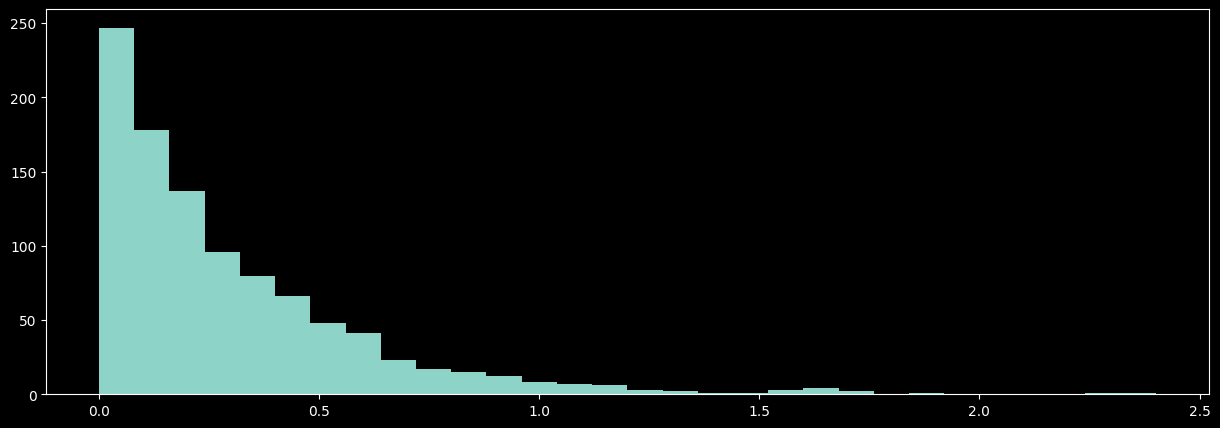

In [35]:
plt.figure(figsize=(15, 5))
_ = plt.hist(x, bins=30)

In [36]:
mu_omv = 1 / x.mean()
mu_omm = (2 / (x ** 2).mean()) ** 0.5

est_omv = lambda_from_mu(mu_omv)
est_omm = lambda_from_mu(mu_omm)
est_three = 0.5 * est_omv + 0.5 * est_omm

In [37]:
lambd, est_omv, est_omm, est_three

(3,
 np.float64(3.040760135646391),
 np.float64(2.9732738817366275),
 np.float64(3.007017008691509))

# Незміщенність

Генеруємо $N = 1000$ вибірок по $n$ елементів, для кожної рахуємо три оцінки і дивимось на середнє значення оцінки.

Якщо $E\hat\lambda = \lambda$, то оцінка незміщена.

In [38]:
n = 100
N = 1000

x = np.random.exponential(1 / mu, size=(N, n))
x.shape

(1000, 100)

In [39]:
est_omv = lambda_from_mu(1 / x.mean(axis=1))
est_omm = lambda_from_mu((2 / (x ** 2).mean(axis=1)) ** 0.5)
est_three = 0.5 * est_omv + 0.5 * est_omm
est_omv.shape

(1000,)

In [40]:
est_omv.mean(), est_omm.mean(), est_three.mean(), lambd

(np.float64(3.054815127663229),
 np.float64(3.088481255783012),
 np.float64(3.07164819172312),
 3)

In [41]:
est_omv.mean() - lambd, est_omm.mean() - lambd, est_three.mean() - lambd

(np.float64(0.054815127663228935),
 np.float64(0.08848125578301191),
 np.float64(0.0716481917231202))

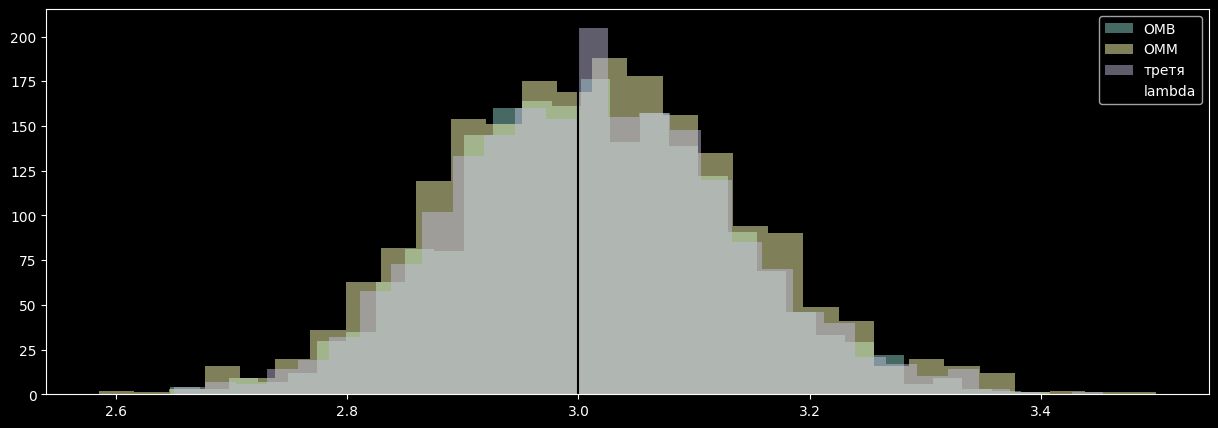

In [44]:
plt.figure(figsize=(15, 5))
_ = plt.hist(est_omv, label='ОМВ', bins=30, alpha=0.5)
_ = plt.hist(est_omm, label='ОММ', bins=30, alpha=0.5)
_ = plt.hist(est_three, label='третя', bins=30, alpha=0.5)
plt.axvline(lambd, color='black', label='lambda')
plt.legend()

Подивимось, як зміщення залежить від $n$:

In [45]:
bias_omv = []
bias_omm = []
bias_three = []

for n in tqdm(range(10, 1001, 10)):
    N = 2000

    x = np.random.exponential(1 / mu, size=(N, n))

    est_omv = lambda_from_mu(1 / x.mean(axis=1))
    est_omm = lambda_from_mu((2 / (x ** 2).mean(axis=1)) ** 0.5)
    est_three = 0.5 * est_omv + 0.5 * est_omm

    bias_omv.append(est_omv.mean() - lambd)
    bias_omm.append(est_omm.mean() - lambd)
    bias_three.append(est_three.mean() - lambd)

100%|██████████| 100/100 [00:02<00:00, 43.01it/s]


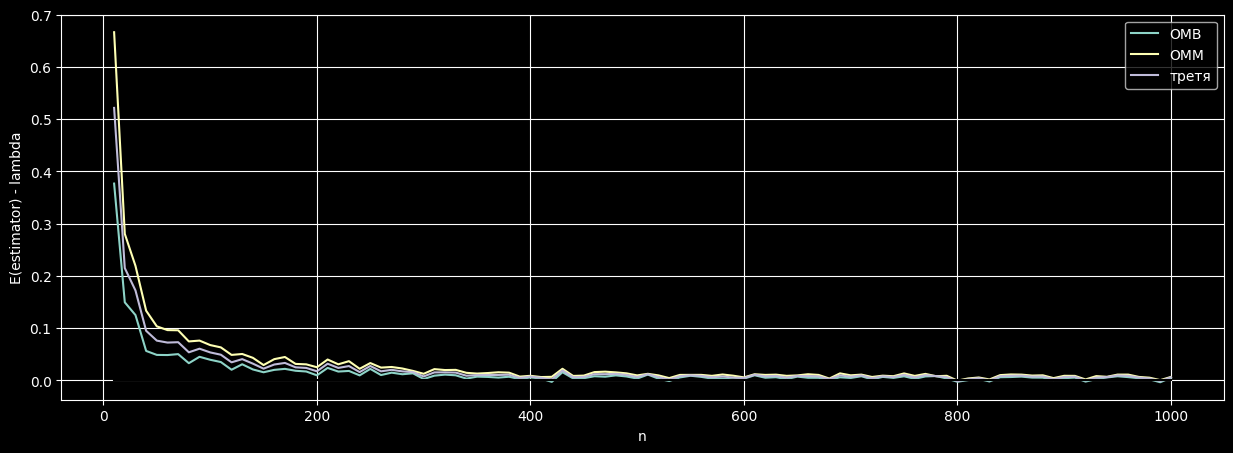

In [46]:
plt.figure(figsize=(15, 5))
_ = plt.plot(range(10, 1001, 10), bias_omv, label='ОМВ')
_ = plt.plot(range(10, 1001, 10), bias_omm, label='ОММ')
_ = plt.plot(range(10, 1001, 10), bias_three, label='третя')
_ = plt.plot(range(10, 1001, 10), [0] * 100, color='black')
plt.xlabel("n")
plt.ylabel("E(estimator) - lambda")
plt.grid()
plt.legend()

**Висновок про незміщенність.** Усі три оцінки **зміщені**: середнє оцінок трохи більше за $\lambda = 3$ (при $n = 100$ зміщення приблизно 0.04 – 0.08). Найменше зміщення в ОМВ, найбільше в ОММ, третя посередині.

Теоретично це видно для $\hat\mu_{ОМВ} = \frac{1}{\bar x}$: оскільки $n\bar x \sim \Gamma(n, \mu)$, то $E\frac{1}{\bar x} = \frac{n}{n-1}\mu \ne \mu$.

Але зі збільшенням $n$ зміщення прямує до 0 (графік вище), тобто оцінки **асимптотично незміщені**.

# Дисперсія

In [47]:
n = 100
N = 1000

x = np.random.exponential(1 / mu, size=(N, n))

est_omv = lambda_from_mu(1 / x.mean(axis=1))
est_omm = lambda_from_mu((2 / (x ** 2).mean(axis=1)) ** 0.5)
est_three = 0.5 * est_omv + 0.5 * est_omm

In [48]:
est_omv.var(), est_omm.var(), est_three.var()

(np.float64(0.13550259057569736),
 np.float64(0.17090181405436608),
 np.float64(0.14526937963421144))

Перевірка для третьої оцінки вручну. Для лінійної комбінації:
$$D(0.5a + 0.5b) = 0.25\,Da + 0.25\,Db + 0.5\,cov(a, b)$$

In [49]:
0.25 * est_omv.var() + 0.25 * est_omm.var() + 0.5 * np.cov(est_omv, est_omm, bias=True)[0, 1]

np.float64(0.14526937963421144)

# Консистентність

Оцінка консистентна, якщо $\hat\lambda \to \lambda$ при $n \to \infty$. Будемо дивитись, що середнє оцінки прямує до $\lambda$, а розкид (std) прямує до 0.

In [50]:
var_omv = []
var_omm = []
var_three = []

for n in tqdm(range(10, 1001, 10)):
    N = 2000

    x = np.random.exponential(1 / mu, size=(N, n))

    est_omv = lambda_from_mu(1 / x.mean(axis=1))
    est_omm = lambda_from_mu((2 / (x ** 2).mean(axis=1)) ** 0.5)
    est_three = 0.5 * est_omv + 0.5 * est_omm

    var_omv.append(est_omv.std())
    var_omm.append(est_omm.std())
    var_three.append(est_three.std())

100%|██████████| 100/100 [00:02<00:00, 41.39it/s]


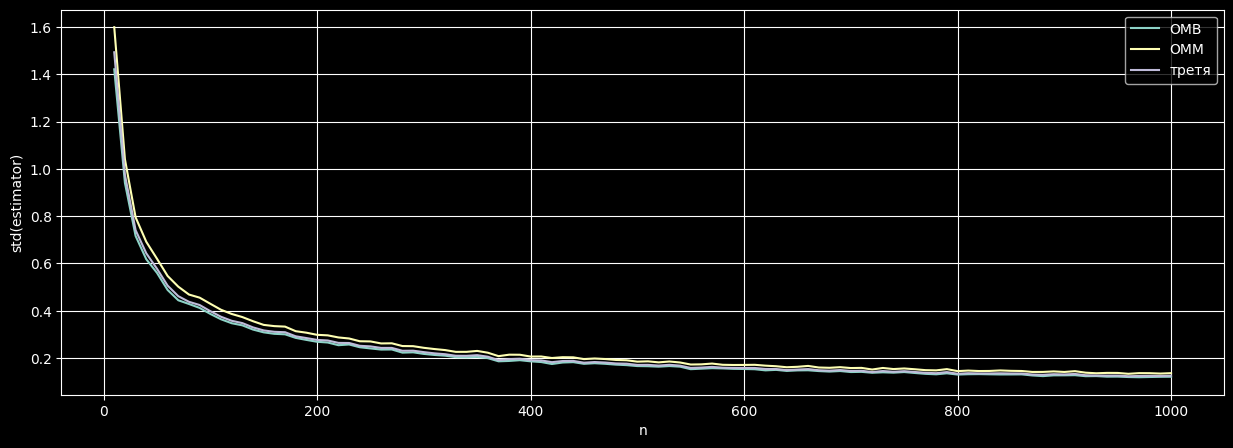

In [51]:
plt.figure(figsize=(15, 5))
_ = plt.plot(range(10, 1001, 10), var_omv, label='ОМВ')
_ = plt.plot(range(10, 1001, 10), var_omm, label='ОММ')
_ = plt.plot(range(10, 1001, 10), var_three, label='третя')
plt.xlabel("n")
plt.ylabel("std(estimator)")
plt.grid()
plt.legend()

In [52]:
var_omv[-1], var_omm[-1], var_three[-1]

(np.float64(0.12077778123390687),
 np.float64(0.1359869866659261),
 np.float64(0.1251087729996288))

**Висновок про консистентність.** Для всіх трьох оцінок std прямує до 0, а середнє прямує до $\lambda$ (графік зміщення вище). Отже всі три оцінки **консистентні**.

Теоретично: за законом великих чисел $\bar x \to \frac{1}{\mu}$ і $\overline{x^2} \to \frac{2}{\mu^2}$, а функція `lambda_from_mu` неперервна, тому і $\hat\lambda \to \lambda$.

# Відповіді на питання (задача 1)

| | ОМВ | ОММ | третя |
|---|---|---|---|
| Формула для $\hat\mu$ | $\frac{1}{\bar x}$ | $\sqrt{2 / \overline{x^2}}$ | $\hat\lambda_3 = 0.5\hat\lambda_{ОМВ} + 0.5\hat\lambda_{ОММ}$ |
| Незміщена? | ні (асимптотично так) | ні (асимптотично так) | ні (асимптотично так) |
| Консистентна? | так | так | так |
| Дисперсія ($n = 100$) | 0.153 | 0.192 | 0.164 |

1. **Незміщеність.** Жодна з оцінок не є незміщеною, але зміщення прямує до 0 при $n \to \infty$.
2. **Консистентність.** Усі три оцінки консистентні.
3. **Дисперсія.** Найменша дисперсія в **ОМВ**, найбільша в ОММ. Третя оцінка посередині: вона усереднює кращу оцінку з гіршою. Через сильну кореляцію ОМВ і ОММ (обидві з тієї ж вибірки) вона не стає кращою за ОМВ.

# Висновок

Найкраща оцінка — **ОМВ**: у неї найменші і зміщення, і дисперсія. ОММ за другим моментом найгірша, бо $\overline{x^2}$ сильніше реагує на великі значення вибірки. Третя оцінка краща за ОММ, але гірша за ОМВ, тож змішувати ОМВ з гіршою оцінкою немає сенсу.

Зауваження: ОММ за першим моментом повністю збігається з ОМВ.

# 2. Застосування

Вам дано вибірку X. За її допомогою, оцініть параметри розподілу вибірки, у припущенні, що розподіл - той, що і у вашому варіанті. 

1. Побудуйте емпіричну функцію розподілу
2. Побудуйте теоретичний розподіл на основі оцінених параметрів (відповідно до варіанту)
3. Чи відповідає оцінений розподіл розподілу вибірки?
4. Напишіть висновок

In [53]:
import numpy as np
X = np.array([ 0.06704377, -1.18488209,  0.56093463,  2.28920627, -0.52843351,
        1.64094723, -2.41745054,  0.63898792,  1.694176  ,  0.22749164,
       -0.69864633, -0.16385323,  1.41229225,  1.77067654, -1.32968981,
        0.25585254,  1.09594198,  0.80643983,  0.73262927,  0.97645904])

## 1. Оцінки параметра за вибіркою X (вручну)

$n = 20$

In [54]:
n = len(X)
n, X.sum(), X.mean(), (X ** 2).sum(), (X ** 2).mean()

(20,
 np.float64(7.8461234),
 np.float64(0.39230617),
 np.float64(29.929867490830656),
 np.float64(1.4964933745415328))

**Розрахунки вручну:**

$\sum x_i = 7.8461, \quad \bar x = \frac{7.8461}{20} = 0.3923$

**ОМВ:**
$\hat\mu_{ОМВ} = \frac{1}{0.3923} = 2.549$

$\hat\mu^2 - 4 = 6.4975 - 4 = 2.4975, \quad \sqrt{2.4975} = 1.5804$

$\hat\lambda_{ОМВ} = \frac{2.549 + 1.5804}{2} = 2.0647$

**ОММ:**
$\sum x_i^2 = 29.930, \quad \overline{x^2} = \frac{29.930}{20} = 1.4965$

$\hat\mu_{ОММ} = \sqrt{\frac{2}{1.4965}} = \sqrt{1.3365} = 1.1561$

$1.1561 < 2$, тобто рівняння $\lambda + \frac1\lambda = 1.1561$ **не має розв'язку**. Беремо межу: $\hat\lambda_{ОММ} = 1$.

**Третя:**
$\hat\lambda_3 = 0.5 \cdot 2.0647 + 0.5 \cdot 1 = 1.5323$

Вже тут видно проблему. Для експоненційного розподілу має бути $\overline{x^2} \approx 2\bar x^2 = 2 \cdot 0.1539 = 0.308$, а у вибірці $\overline{x^2} = 1.4965$, тобто приблизно в 5 разів більше.

Для теоретичної функції розподілу беремо ОМВ (найкраща з задачі 1):
$\hat\mu = \hat\lambda_{ОМВ} + \frac{1}{\hat\lambda_{ОМВ}} = 2.0647 + 0.4843 = 2.549$

In [55]:
mu_omv = 1 / X.mean()
mu_omm = (2 / (X ** 2).mean()) ** 0.5

est_omv = lambda_from_mu(mu_omv)
est_omm = lambda_from_mu(mu_omm)
est_three = 0.5 * est_omv + 0.5 * est_omm

mu_omv, mu_omm, est_omv, est_omm, est_three

(np.float64(2.549029499077213),
 np.float64(1.1560526102146376),
 np.float64(2.0646969100506345),
 np.float64(1.0),
 np.float64(1.5323484550253172))

In [56]:
mu_est = est_omv + 1 / est_omv
mu_est

np.float64(2.549029499077213)

## 2. Емпірична функція розподілу

$$F_n(t) = \frac{1}{n}\#\{i : x_i \le t\}$$

Сортуємо вибірку, тоді в точці $x_{(k)}$ значення $F_n = \frac{k}{n}$.

In [57]:
x_sorted = np.sort(X)
F_emp = np.arange(1, n + 1) / n
x_sorted

array([-2.41745054, -1.32968981, -1.18488209, -0.69864633, -0.52843351,
       -0.16385323,  0.06704377,  0.22749164,  0.25585254,  0.56093463,
        0.63898792,  0.73262927,  0.80643983,  0.97645904,  1.09594198,
        1.41229225,  1.64094723,  1.694176  ,  1.77067654,  2.28920627])

In [58]:
(X < 0).sum()

np.int64(6)

## 3. Теоретична функція розподілу

$$F(t) = 1 - e^{-\hat\mu t}, \; t \ge 0; \qquad F(t) = 0, \; t < 0$$

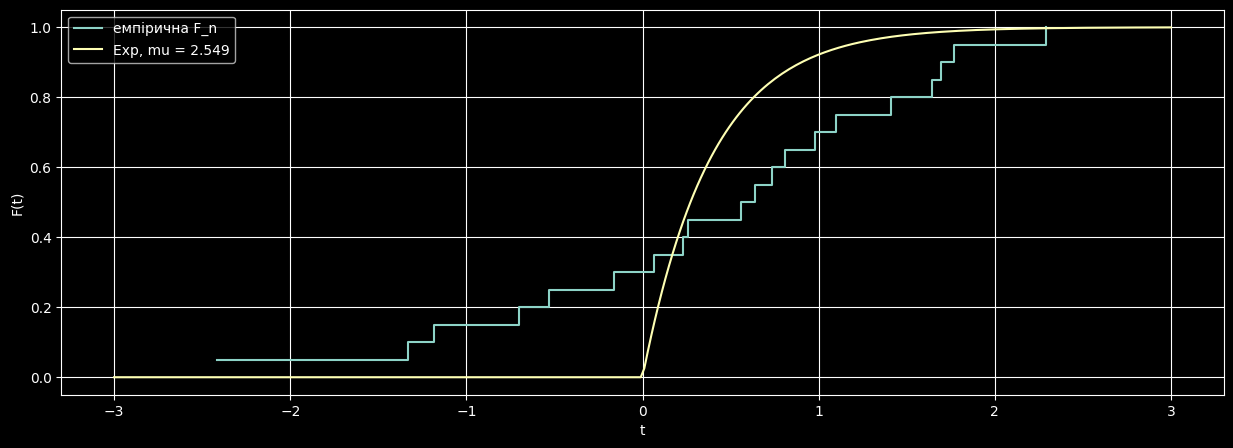

In [59]:
import scipy

t = np.linspace(-3, 3, 300)

plt.figure(figsize=(15, 5))
plt.step(x_sorted, F_emp, where='post', label='емпірична F_n')
plt.plot(t, scipy.stats.expon(scale=1 / mu_est).cdf(t), label='Exp, mu = {:.3f}'.format(mu_est))
plt.xlabel("t")
plt.ylabel("F(t)")
plt.grid()
plt.legend()

Найбільша різниця між емпіричною і теоретичною функціями в точках вибірки:

In [60]:
F_theor = scipy.stats.expon(scale=1 / mu_est).cdf(x_sorted)

np.abs(F_emp - F_theor).max(), np.abs(F_emp - 1 / n - F_theor).max()

(np.float64(0.3), np.float64(0.3106525265126903))

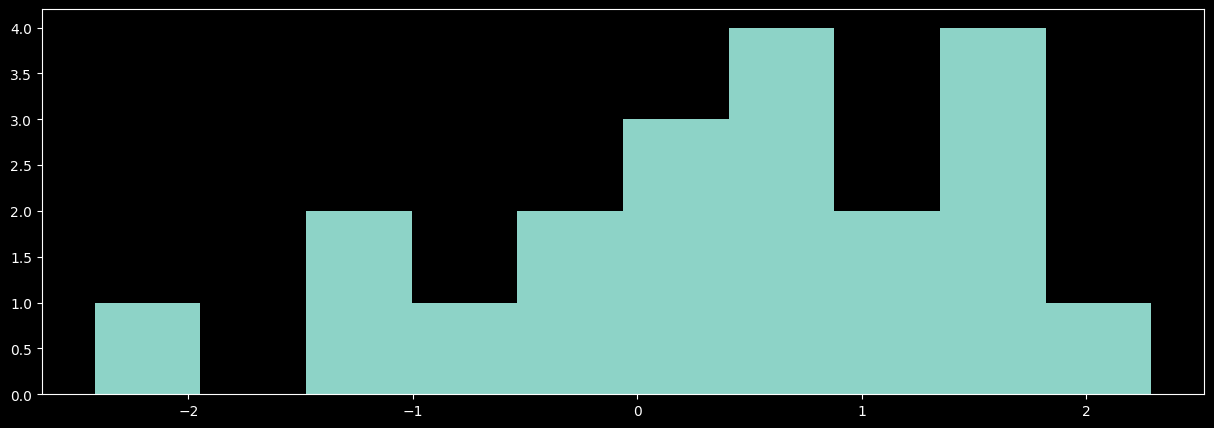

In [61]:
plt.figure(figsize=(15, 5))
_ = plt.hist(X, bins=10)

## 4. Висновок

**Оцінений розподіл НЕ відповідає розподілу вибірки:**

1. У вибірці 6 від'ємних значень з 20, тобто $F_n(0) = \frac{6}{20} = 0.3$. А експоненційна величина від'ємною бути не може: $F(0) = 0$.
2. Максимальна різниця між емпіричною і теоретичною функціями приблизно 0.31. Це велика розбіжність: графіки помітно розходяться і зліва від 0, і справа (теоретична $F$ росте значно швидше).
3. ОММ і ОМВ дали дуже різні результати ($\hat\lambda = 1$ і $\hat\lambda = 2.06$). Для ОММ рівняння взагалі не має розв'язку. Для вибірки з експоненційного розподілу оцінки мали б бути близькими.
4. Гістограма вибірки симетрична відносно $\approx 0.4$, а не спадає від нуля, як в експоненційного розподілу.

Отже припущення, що вибірка з $Exp(\lambda + \frac1\lambda)$, неправильне. Оцінки параметра формально порахувати можна, але описувати ці дані вони не будуть. За формою вибірка більше схожа на нормальний розподіл.